In [5]:
##### Figure SI: exposed vs overall capital, labor, production by deprivation percentile

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import to_rgb
from scipy.signal import savgol_filter

In [6]:
##### LOAD DATA

ROOT = Path.cwd().parent
dist_df = pd.read_csv(ROOT / "Results/30x30/exposure_by_deprivation_percentile.csv")

FIG_DIR = ROOT / "Figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

In [7]:
##### STYLING AND HELPERS

COLORS = {
    "Capital": "#2F7C87",
    "Labor": "#C96A3B",
    "Production": "#E5E5E5",
}
PRODUCTION_EDGE = "#C4C4C4"
REFERENCE_COLOR = "#888888"

def smooth(series, window=9, polyorder=2):
    smoothed = savgol_filter(series.values, window_length=window, polyorder=polyorder, mode="interp")
    return pd.Series(smoothed, index=series.index)

def get_series(basis, region, variable, area, estimate="core"):
    sub = dist_df[
        (dist_df["pctl_basis"] == basis) & (dist_df["region"] == region)
        & (dist_df["variable"] == variable) & (dist_df["area"] == area)
        & (dist_df["estimate"] == estimate)
    ].sort_values("percentile")
    return smooth(sub.set_index("percentile")["pct_of_total"])

def lighten(hex_color, amount=0.7):
    rgb = np.array(to_rgb(hex_color))
    return tuple(rgb + (1 - rgb) * amount)

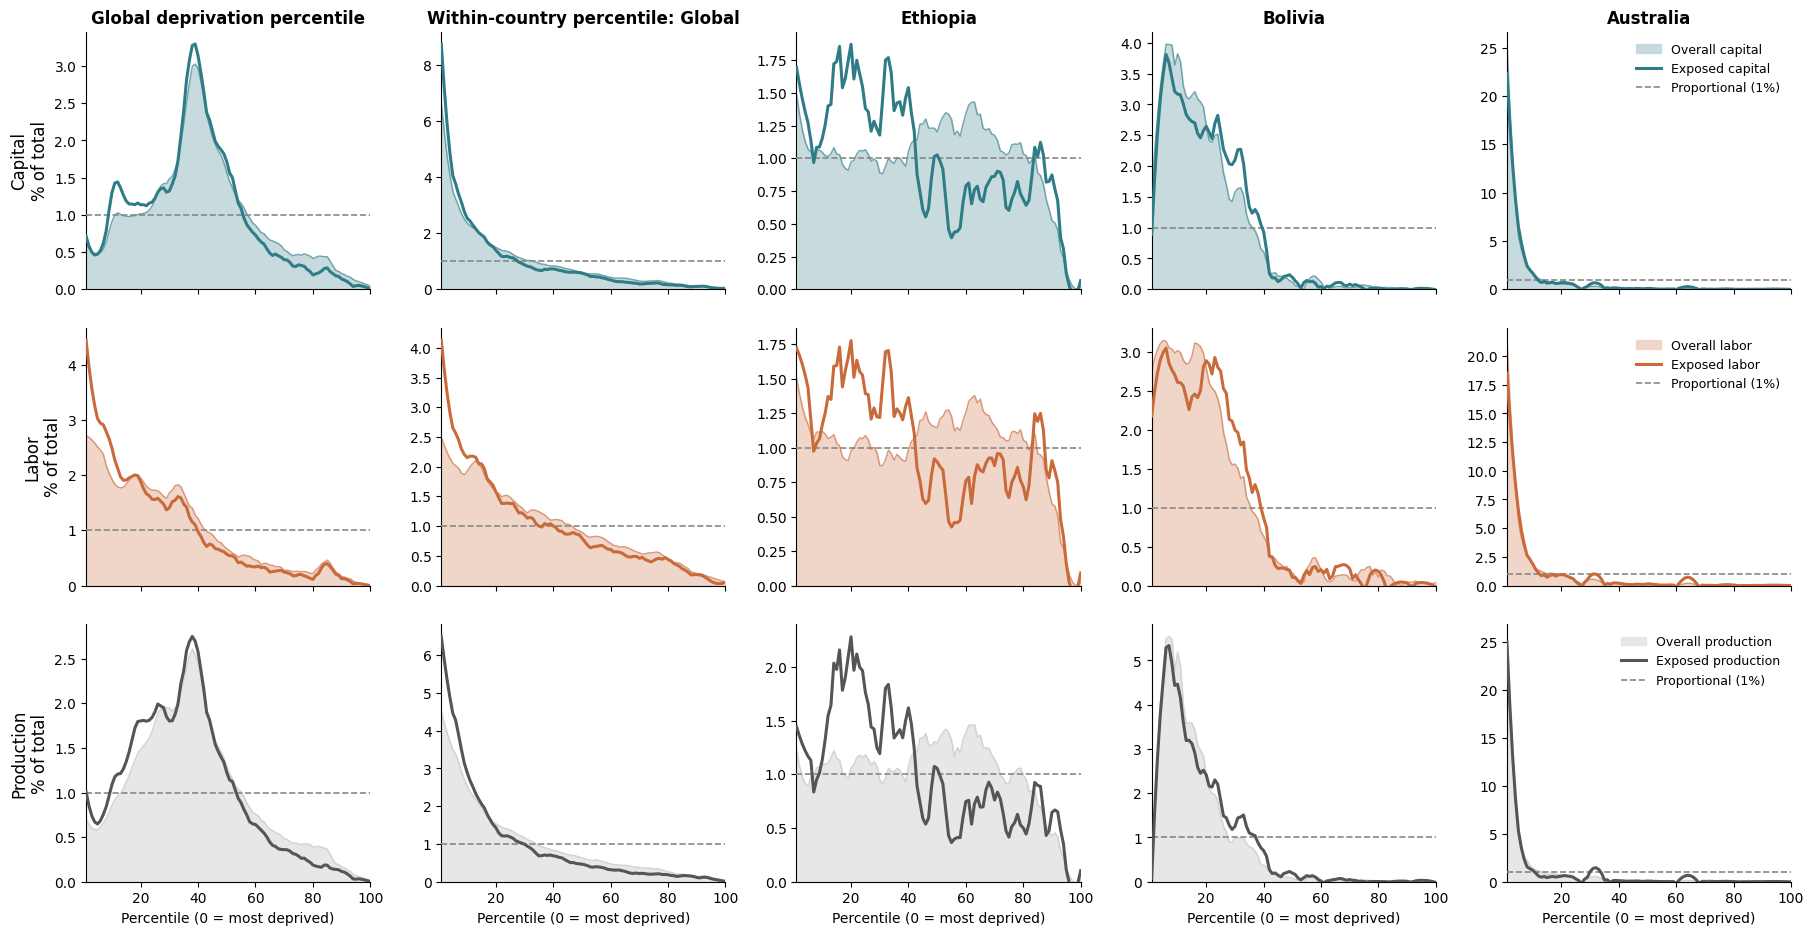

In [8]:
##### FIGURE SI

##### SPECS

# (variable, line color, fill color)
VAR_SPECS = [
    ("Capital",    COLORS["Capital"], lighten(COLORS["Capital"])),
    ("Labor",      COLORS["Labor"],   lighten(COLORS["Labor"])),
    ("Production", "#555555",         COLORS["Production"]),
]

# (column title, percentile basis, region)
COL_SPECS = [
    ("Global deprivation percentile",     "global",   "Global"),
    ("Within-country percentile: Global", "national", "Global"),
    ("Ethiopia",                          "national", "ETH"),
    ("Bolivia",                           "national", "BOL"),
    ("Australia",                         "national", "AUS"),
]

fig, axes = plt.subplots(3, 5, figsize=(22, 10), sharey=False, sharex=True)

for r, (var_name, line_color, fill_color) in enumerate(VAR_SPECS):
    for c, (col_title, basis, region) in enumerate(COL_SPECS):
        ax = axes[r, c]

        overall = get_series(basis, region, var_name, "overall")
        exposed = get_series(basis, region, var_name, "exposed")

        ax.fill_between(overall.index, overall.values, color=fill_color, alpha=0.9,
                        zorder=1, label=f"Overall {var_name.lower()}")
        ax.plot(overall.index, overall.values,
                color=PRODUCTION_EDGE if var_name == "Production" else line_color,
                lw=1.0, alpha=0.6, zorder=2)
        ax.plot(exposed.index, exposed.values, color=line_color, lw=2.2, zorder=4,
                label=f"Exposed {var_name.lower()}")
        ax.axhline(1, color=REFERENCE_COLOR, lw=1.2, ls="--", zorder=3,
                   label="Proportional (1%)")

        ax.set_xlim(1, 100)
        ax.set_ylim(bottom=0)
        ax.spines[["top", "right"]].set_visible(False)
        ax.tick_params(labelsize=10)

        if r == 0:
            ax.set_title(col_title, fontweight="bold", fontsize=12)
        if c == 0:
            ax.set_ylabel(f"{var_name}\n% of total", fontsize=12)
        if r == 2:
            ax.set_xlabel("Percentile (0 = most deprived)", fontsize=10)
        if c == len(COL_SPECS) - 1:
            ax.legend(frameon=False, fontsize=9, loc="upper right")

fig.subplots_adjust(hspace=0.15, wspace=0.25, top=0.93, bottom=0.08)
plt.savefig(FIG_DIR / "Figure_SI_exposed_vs_overall.tiff", dpi=300, bbox_inches="tight")
plt.show()